# Guia de uso do cliente WTSS.py

O **WTSS** (*Web Time Series Service*) entrega **séries temporais extraídas de imagens
de satélite**. Você informa uma coordenada e o serviço localiza, em **cada imagem** da
coleção, o **único pixel** que contém aquele ponto. A série é a sequência desses pixels
ao longo do tempo: **um valor por imagem**, sempre na mesma posição geográfica.

> Não é uma série extraída *de dentro* de uma imagem, nem o download das imagens
> inteiras. De cada imagem da coleção é lido um pixel — e só ele trafega.

Ao consultar uma **área** em vez de um ponto, o serviço devolve **um conjunto de
séries**: uma para cada pixel dentro do polígono, todas construídas dessa mesma maneira.

O mesmo cliente serve **vários satélites** — Sentinel-2, Landsat, CBERS, TERRA e AQUA —
e **várias variáveis** — índices de vegetação (NDVI, EVI), refletâncias por banda, até
temperatura de superfície. Este notebook é **genérico**: você escolhe a coleção e a série
numa célula de configuração, e todo o resto funciona igual.

> **Sobre TERRA e AQUA:** as coleções `mod*` e `myd*` são geradas pelo sensor **MODIS**,
> que não é um satélite e sim um instrumento a bordo de dois deles — `mod*` vem do MODIS
> do **TERRA** e `myd*` do MODIS do **AQUA**.

**O que o guia apresenta:**
1. conceitos básicos (coleção, banda, série);
2. o que o servidor oferece;
3. recuperação de uma série (ponto e área);
4. trabalho com os dados (`pandas`/`xarray`);
5. visualização (série, mapa, estatísticas, gráfico interativo);
6. aplicação do código a vários sensores;
7. uso da linha de comando (CLI).

## 1. Conceitos-chave

| Conceito | O que é |
| --- | --- |
| **Serviço** (`WTSS`) | O servidor que você acessa, identificado por uma URL. |
| **Coleção / *coverage*** | Um produto de satélite já processado (ex.: `S2-16D-2` = Sentinel-2 a cada 16 dias). |
| **Banda / atributo** | Uma variável dentro da coleção (ex.: `NDVI`, `EVI`, `red`, `LST_Day_1km`). |
| ***Timeline*** | As datas em que há observação — uma imagem por data. |
| **Consulta por ponto** | Uma série para uma coordenada: o pixel que contém o ponto é lido em cada imagem da coleção, um valor por imagem. |
| **Consulta por área** | Um conjunto de séries, cada uma proveniente de um pixel dentro do polígono — habilita mapa e estatística. |
| **`nodata` / `scale`** | Valor reservado que marca "sem dado" (nuvem, falha na aquisição) e fator de escala, ambos descritos nos metadados da banda. O cliente pode remover os valores ausentes (`mask_nodata`) e converter os números à unidade física da banda (`apply_scale`). |

## 2. Instalação

Esta é a versão reformulada do cliente, ainda não publicada no PyPI — instale direto do
repositório, a partir da branch de desenvolvimento do TG:

In [1]:
# Cliente reformulado (descomente para instalar):
# %pip install "git+https://github.com/suellen-m-almeida/inpe-proj.git@tg/melhorias"

# Com os extras usados neste guia (gráfico interativo, xarray e exportadores):
# %pip install "wtss[interactive,xarray,io] @ git+https://github.com/suellen-m-almeida/inpe-proj.git@tg/melhorias"

# Bibliotecas de apoio às figuras:
# %pip install matplotlib geopandas netCDF4 contextily

In [2]:
# (célula de configuração; oculta no relatório) Gráficos inline e silêncio de
# avisos cosméticos do matplotlib que não afetam os dados.
%matplotlib inline
import warnings
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')
warnings.filterwarnings('ignore', message='apply_scale=True')

## 3. Conectar ao serviço

Importe `WTSS` e aponte para a URL do servidor.

> **Token de acesso:** coleções autenticadas do Brazil Data Cube exigem `access_token='SEU_TOKEN'` (obtido em https://brazildatacube.dpi.inpe.br/portal/ ).

In [3]:
from wtss import WTSS

service = WTSS('https://data.inpe.br/bdc/wtss/v4/')
# service = WTSS('https://data.inpe.br/bdc/wtss/v4/', access_token='SEU_TOKEN')
service

wtss(url="https://data.inpe.br/bdc/wtss/v4/",validate=False,access_token=None)

## 4. Descobrir o que o servidor oferece

Antes de consultar, **descubra**. O atributo `coverages` lista todas as coleções — de sensores diferentes:

In [4]:
service.coverages

['CBERS4-MUX-2M-1',
 'CBERS4-WFI-16D-2',
 'CBERS-WFI-8D-1',
 'LANDSAT-16D-1',
 'mod11a2-6.1',
 'mod13q1-6.1',
 'myd11a2-6.1',
 'myd13q1-6.1',
 'S2-16D-2']

Um pequeno laço mostra, para cada coleção, **as bandas e o período** disponíveis (repare que quase todas têm `NDVI` e `EVI`):

In [5]:
for nome in service.coverages:
    cv = service[nome]
    bandas = [b['name'] for b in cv.attributes]
    tl = cv.timeline
    print(f'{nome:18s} | {tl[0]} -> {tl[-1]} ({len(tl):4d} datas) | bandas: {bandas[:6]}...')

CBERS4-MUX-2M-1    | 2016-01-01 -> 2026-07-01 (  64 datas) | bandas: ['BAND5', 'BAND6', 'BAND7', 'BAND8', 'NDVI', 'CMASK']...
CBERS4-WFI-16D-2   | 2016-01-01 -> 2026-09-14 ( 247 datas) | bandas: ['BAND13', 'BAND14', 'CMASK', 'CLEAROB', 'TOTALOB', 'PROVENANCE']...
CBERS-WFI-8D-1     | 2020-01-01 -> 2026-09-22 ( 310 datas) | bandas: ['BAND13', 'CMASK', 'CLEAROB', 'TOTALOB', 'DATASOURCE', 'PROVENANCE']...


LANDSAT-16D-1      | 1990-01-01 -> 2026-08-29 ( 515 datas) | bandas: ['NDVI', 'coastal', 'qa_pixel', 'CLEAROB', 'TOTALOB', 'PROVENANCE']...
mod11a2-6.1        | 2000-02-18 -> 2026-09-06 (1221 datas) | bandas: ['LST_Day_1km', 'QC_Day', 'Day_view_time', 'Day_view_angl', 'Clear_sky_days', 'LST_Night_1km']...
mod13q1-6.1        | 2000-02-18 -> 2026-08-29 ( 611 datas) | bandas: ['NDVI', 'EVI', 'VI_Quality', 'composite_day_of_the_year', 'pixel_reliability', 'blue_reflectance']...


myd11a2-6.1        | 2002-07-04 -> 2026-09-06 (1112 datas) | bandas: ['LST_Day_1km', 'QC_Day', 'Day_view_time', 'Day_view_angl', 'LST_Night_1km', 'QC_Night']...
myd13q1-6.1        | 2002-07-04 -> 2026-08-21 ( 556 datas) | bandas: ['NDVI', 'EVI', 'blue_reflectance', 'red_reflectance', 'NIR_reflectance', 'VI_Quality']...
S2-16D-2           | 2017-01-01 -> 2026-09-14 ( 224 datas) | bandas: ['CLEAROB', 'TOTALOB', 'PROVENANCE', 'SCL', 'B01', 'B02']...


## 5. ⚙️ Configuração — escolha aqui a sua série

**Esta é a única célula que você precisa editar.** Tudo abaixo usa estas variáveis, então
para trocar de satélite basta mudar `COBERTURA` e `ATRIBUTO`.

A consulta por ponto usa `LATITUDE`/`LONGITUDE`; a consulta por área usa a `BBOX`, um
*bounding box* declarado explicitamente como `(oeste, sul, leste, norte)`.

> **Dica de área:** o servidor limita a área do polígono, e o limite é o mesmo para todas
> as coleções: acima dele, a consulta volta com erro 400, e o cliente repassa a mensagem do
> servidor com o motivo. A célula logo depois da configuração mede isso. Ela consulta uma
> caixa pequena no Sentinel-2 e uma maior no MODIS, dentro do limite, e uma acima dele em
> cada coleção, e imprime a resolução de cada uma, lida dos metadados. A resolução muda
> quantos pixels cabem na área, não o tamanho permitido.

In [6]:
COBERTURA = 'S2-16D-2'        # experimente: 'LANDSAT-16D-1', 'mod13q1-6.1', 'CBERS-WFI-8D-1'
ATRIBUTO  = 'NDVI'            # veja as bandas da coleção no laço acima

# Consulta por ponto — uma coordenada.
LATITUDE  = -12.0
LONGITUDE = -54.0

# Consulta por área — bounding box explícito: (oeste, sul, leste, norte).
BBOX = (-54.000, -12.000, -53.995, -11.995)

INICIO = '2021-01-01'
FIM    = '2021-12-31'

coverage = service[COBERTURA]
print(f'Coleção: {COBERTURA} | atributo: {ATRIBUTO}')
print('Bandas disponíveis:', [b['name'] for b in coverage.attributes])

Coleção: S2-16D-2 | atributo: NDVI
Bandas disponíveis: ['CLEAROB', 'TOTALOB', 'PROVENANCE', 'SCL', 'B01', 'B02', 'B04', 'B08', 'B8A', 'B09', 'B03', 'B11', 'B12', 'EVI', 'NDVI', 'NBR', 'B05', 'B06', 'B07']


In [7]:
import datetime as dt

import requests
import shapely.geometry
from pyproj import Geod

# O limite de área do servidor, medido: duas caixas dentro dele e uma acima, em cada coleção.
geod = Geod(ellps='WGS84')


def caixa_em_torno(lat, lon, lado_graus):
    meio = lado_graus / 2
    return shapely.geometry.box(lon - meio, lat - meio, lon + meio, lat + meio)


def hectares(geom):
    return abs(geod.geometry_area_perimeter(geom)[0]) / 1e4


# Uma janela de 10 dias a partir de INICIO: uma composição, sem a consulta ficar vazia.
FIM_CURTO = (dt.date.fromisoformat(INICIO) + dt.timedelta(days=10)).isoformat()

print('resolução de cada coleção, pelos metadados:')
for nome in service.coverages:
    banda = service[nome].attributes[0]
    print(f'  {nome:18s} {banda.get("resolution_x"):8.2f} m')

print(f'\ndentro do limite ({INICIO} a {FIM_CURTO}):')
for nome, lado in (('S2-16D-2', 0.009), ('mod13q1-6.1', 0.045)):
    caixa = caixa_em_torno(LATITUDE, LONGITUDE, lado)
    serie = service[nome].ts(attributes=['NDVI'], geom=caixa, start_datetime=INICIO,
                             end_datetime=FIM_CURTO).ts
    print(f'  {nome:18s} caixa de {lado}° ({hectares(caixa):,.0f} ha): '
          f'{len(serie.locations)} pixels, {len(serie.timeline)} data(s)')

grande = caixa_em_torno(LATITUDE, LONGITUDE, 0.06)
print(f'\nacima do limite, a mesma caixa de 0.06° ({hectares(grande):,.0f} ha) em cada coleção:')
for nome in service.coverages:
    cobertura = service[nome]
    try:
        cobertura.ts(attributes=[cobertura.attributes[0]['name']], geom=grande,
                     start_datetime=INICIO, end_datetime=FIM_CURTO).ts
        print(f'  {nome:18s} aceita')
    except requests.HTTPError as erro:
        print(f'  {nome:18s} HTTP {erro.response.status_code}: {str(erro).split(" -- ")[-1]}')

resolução de cada coleção, pelos metadados:


  CBERS4-MUX-2M-1       20.00 m
  CBERS4-WFI-16D-2      64.00 m
  CBERS-WFI-8D-1        64.00 m


  LANDSAT-16D-1         30.00 m


  mod11a2-6.1          926.63 m
  mod13q1-6.1          231.66 m
  myd11a2-6.1          926.63 m


  myd13q1-6.1          231.66 m
  S2-16D-2              10.00 m

dentro do limite (2021-01-01 a 2021-01-11):


  S2-16D-2           caixa de 0.009° (98 ha): 9792 pixels, 1 data(s)



  mod13q1-6.1        caixa de 0.045° (2,440 ha): 463 pixels, 1 data(s)

acima do limite, a mesma caixa de 0.06° (4,337 ha) em cada coleção:
  CBERS4-MUX-2M-1    HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.
  CBERS4-WFI-16D-2   HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.
  CBERS-WFI-8D-1     HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.


  LANDSAT-16D-1      HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.
  mod11a2-6.1        HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.
  mod13q1-6.1        HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.


  myd11a2-6.1        HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.
  myd13q1-6.1        HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.
  S2-16D-2           HTTP 400: The polygon area 4336.941992762566 must be less than 3000ha.


## 6. Inspecionar a coleção escolhida

O objeto `Coverage` se mostra como tabela HTML rica em notebook. Também dá para ler os metadados de uma banda (nodata, escala) e a linha do tempo:

In [8]:
banda = coverage.band(ATRIBUTO)
print('metadados da banda:', {k: banda.get(k) for k in ('name', 'nodata', 'scale', 'description')})
print('primeiras datas   :', coverage.timeline[:5])

metadados da banda: {'name': 'NDVI', 'nodata': -9999.0, 'scale': 0.0001, 'description': None}
primeiras datas   : ['2017-01-01', '2017-01-17', '2017-02-02', '2017-02-18', '2017-03-06']


## 7. Recuperar a série temporal (um ponto)

`coverage.ts(...)` monta a consulta; a série executada fica em `.ts`. A consulta é **preguiçosa** — nada vai à rede até você acessar `.ts`.

In [9]:
ts = coverage.ts(attributes=[ATRIBUTO],
                 latitude=LATITUDE, longitude=LONGITUDE,
                 start_datetime=INICIO, end_datetime=FIM).ts
ts

pixel id,timeseries
0,"[0.4094, 0.8863, 0.8686, 0.2397, 0.1666, 0.8541, 0.1298, 0.8801, 0.8726, 0.8683, 0.8619, 0.8759, 0.8817, 0.8771, 0.8677, 0.8844, 0.8374, 0.8352, 0.1194, 0.8961, 0.0081, 0.4969, 0.2111]"


In [10]:
print('valores:', ts.values(ATRIBUTO)[:5], '...')
print('datas  :', ts.timeline[:5], '...')

valores: [[0.4094, 0.8863, 0.8686, 0.2397, 0.1666, 0.8541, 0.1298, 0.8801, 0.8726, 0.8683, 0.8619, 0.8759, 0.8817, 0.8771, 0.8677, 0.8844, 0.8374, 0.8352, 0.1194, 0.8961, 0.0081, 0.4969, 0.2111]] ...
datas  : ['2021-01-01', '2021-01-17', '2021-02-02', '2021-02-18', '2021-03-06'] ...


## 8. Trabalhar com os dados (`pandas` / `xarray`)

A série chega em estruturas já indexadas pela data da observação:

- `ts[ATRIBUTO]` → `pandas.Series` (índice = data, valor = observação);
- `ts.df(format='long'|'wide')` → `pandas.DataFrame`;
- `ts.to_xarray()` → `xarray.Dataset`.

`ts[ATRIBUTO]` devolve a `Series` de uma banda: o índice é a linha do tempo da
coleção, e os valores são as observações daquele pixel.

In [11]:
serie_ndvi = ts[ATRIBUTO]

print('tipo  :', f'{type(serie_ndvi).__module__}.{type(serie_ndvi).__name__}')
print('índice:', type(serie_ndvi.index).__name__)
print('dtype :', serie_ndvi.dtype)

serie_ndvi.head()

tipo  : pandas.Series
índice: DatetimeIndex
dtype : float64


2021-01-01    0.4094
2021-01-17    0.8863
2021-02-02    0.8686
2021-02-18    0.2397
2021-03-06    0.1666
Name: NDVI, dtype: float64

Com o índice temporal, o recorte por período é direto:

In [12]:
serie_ndvi['2021-03':'2021-06']

2021-03-06    0.1666
2021-03-22    0.8541
2021-04-07    0.1298
2021-04-23    0.8801
2021-05-09    0.8726
2021-05-25    0.8683
2021-06-10    0.8619
2021-06-26    0.8759
Name: NDVI, dtype: float64

In [13]:
ts.df(format='long').head()

,,,value
datetime,attribute,location,
2021-01-01,NDVI,"(-53.999953383909094, -12.00004451671349)",0.4094
2021-01-17,NDVI,"(-53.999953383909094, -12.00004451671349)",0.8863
2021-02-02,NDVI,"(-53.999953383909094, -12.00004451671349)",0.8686
2021-02-18,NDVI,"(-53.999953383909094, -12.00004451671349)",0.2397
2021-03-06,NDVI,"(-53.999953383909094, -12.00004451671349)",0.1666


In [14]:
ts.to_xarray()

<xarray.Dataset> Size: 384B
Dimensions:    (time: 23)
Coordinates:
  * time       (time) datetime64[us] 184B 2021-01-01 2021-01-17 ... 2021-12-19
    longitude  float64 8B -54.0
    latitude   float64 8B -12.0
Data variables:
    NDVI       (time) float64 184B 0.4094 0.8863 0.8686 ... 0.0081 0.4969 0.2111

## 9. Consulta por área (polígono) + estatística

Passando `geom`, o servidor devolve **todos os pixels** da área. Isso habilita o mapa e as estatísticas por data (mediana, quartis, média, desvio), obtidas com `summarize(...)`.

In [15]:
import shapely.geometry

# O bounding box definido na configuração, sem buffer em torno do ponto.
poly = shapely.geometry.box(*BBOX)

serie = coverage.ts(attributes=[ATRIBUTO], geom=poly,
                    start_datetime=INICIO, end_datetime=FIM).ts
resumo = coverage.summarize(attributes=[ATRIBUTO], geom=poly,
                            start_datetime=INICIO, end_datetime=FIM)
print('pixels retornados na área:', len(serie.df(format='wide').columns))

pixels retornados na área: 3024


## 10. Visualização

Os mesmos métodos para **qualquer coleção/série**. Cada figura mostra uma faceta do dado.

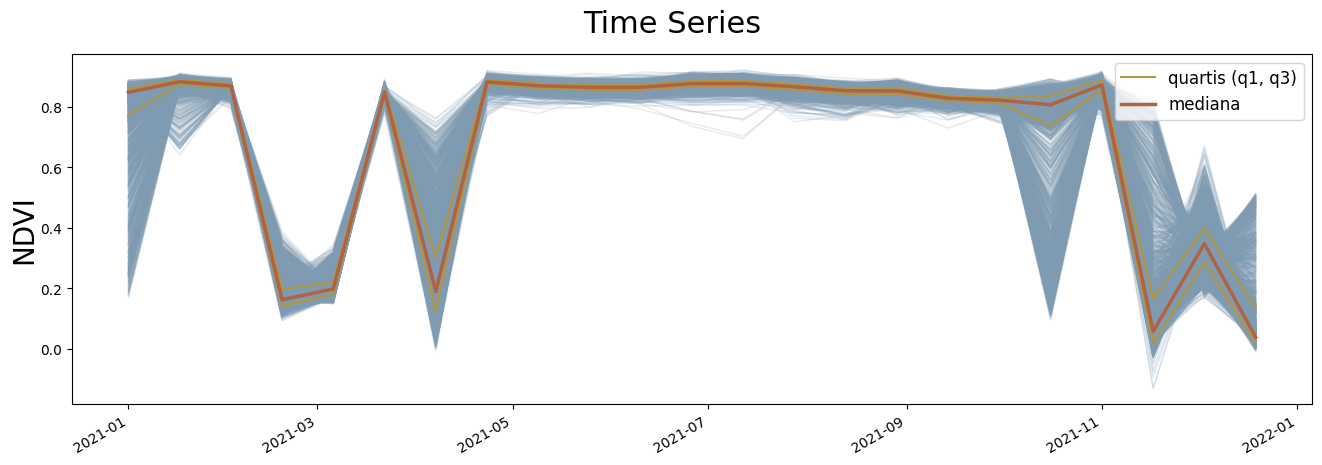

In [16]:
# 10.1 Todas as séries da área: uma linha por pixel, com mediana e quartis por cima.
#      É o comportamento padrão de plot() -- o parâmetro pixels vem como True.
serie.plot()

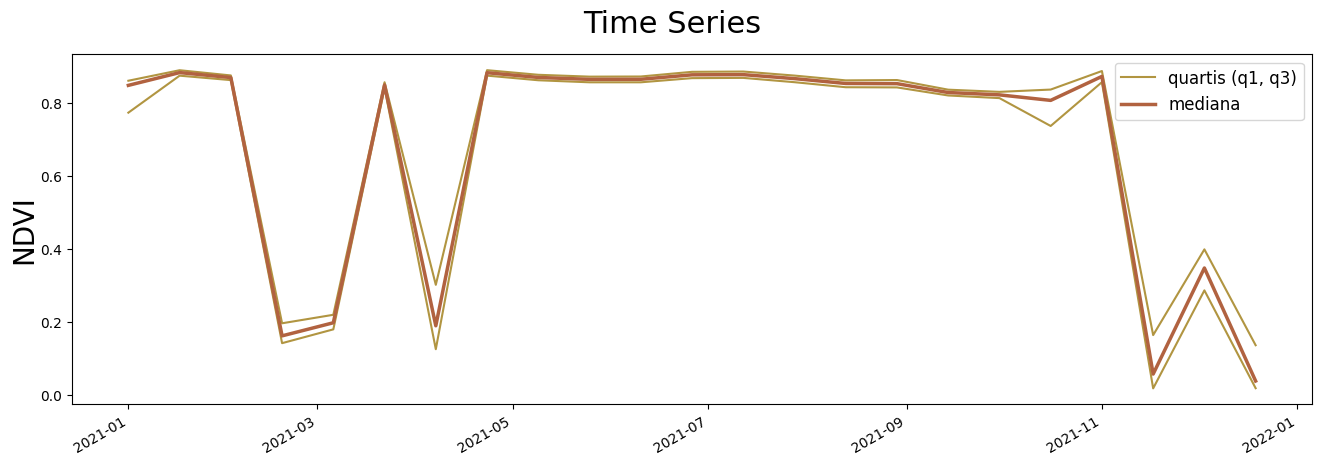

In [17]:
# 10.2 Só a estatística: mesma informação sem o feixe de pixels, mais limpo
#      quando a área tem muitos pixels.
serie.plot(pixels=False)

<Axes: title={'center': 'S2-16D-2 — NDVI (mean over timeline)'}, xlabel='longitude', ylabel='latitude'>

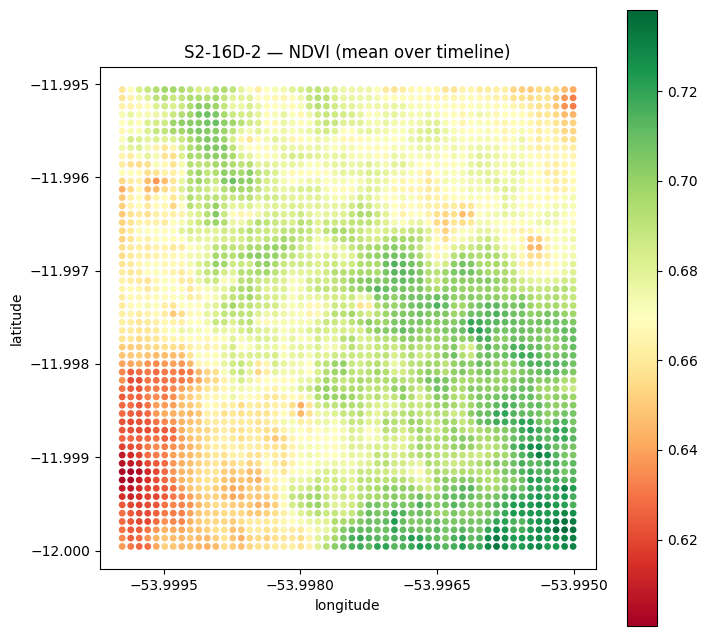

In [18]:
# 10.3 Mapa espacial: cada pixel colorido pelo valor médio no período.
#      reduce aceita 'mean', 'median', 'min', 'max' e 'std' -- com 'std' a cor
#      passa a ser o quanto cada pixel variou, em vez do seu nível.
serie.plot_map(ATRIBUTO, reduce='mean', cmap='RdYlGn', markersize=15)

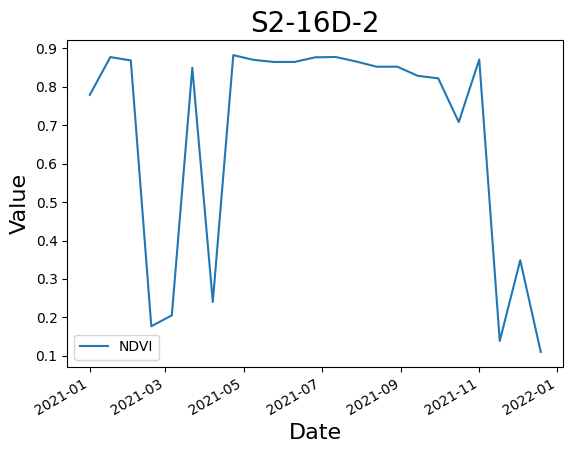

In [19]:
# 10.4 Estatística agregada: escolha a agregação (mean/median/min/max) ou compare bandas
resumo.plot(attributes=[ATRIBUTO], aggregation='mean')

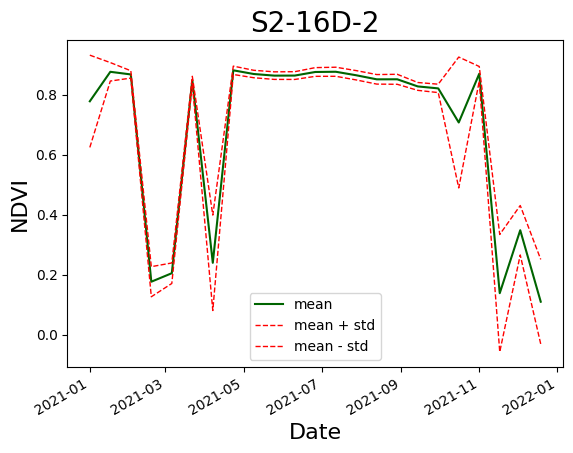

In [20]:
# 10.5 Média +/- desvio-padrão (dispersão entre os pixels da área)
resumo.plot_mean_std(attribute=ATRIBUTO)

### 10.6 Cubo espaço-temporal (polígono → `grid`)

Como o polígono devolve um raster de pixels, `to_xarray(grid=True)` reconstrói um
**cubo `(time, y, x)`** na grade nativa da coleção: `x` e `y` são as coordenadas, em metros,
do centro de cada coluna e de cada linha no CRS da coleção (aqui, a sinusoidal do MODIS),
onde a grade é regular, e o CRS fica em `attrs`. `longitude`/`latitude` continuam como
coordenadas **2D**, porque em lon/lat essa grade não é regular: a célula abaixo mede o
quanto ela é cisalhada. O cubo pode ser visto como um **painel de mapas por data**
(*facet*) ou como um **cubo 3D** com `plot_cube()`.

A caixa lon/lat corta a grade nativa na diagonal, então as linhas cobrem colunas
diferentes e a extensão completa é um paralelogramo. `to_xarray(grid=True)` devolve essa
extensão inteira, com `NaN` onde não há pixel: é o dado como veio, sem descartar nada.

Para **desenhar**, porém, a borda em degraus é lida como estrutura do dado quando na
verdade é o formato da consulta. Por isso as duas figuras abaixo recortam antes de
plotar o **retângulo comum a todas as linhas** — o facet faz esse recorte aqui no
notebook, e o `plot_cube()` já o faz por dentro. O facet desenha sobre os eixos `x`/`y`
nativos, então cada pixel ocupa exatamente a sua célula, sem aproximação.

> Aqui usamos o MODIS do TERRA (`mod13q1-6.1`) e uma janela curta de tempo apenas
> para as figuras ficarem legíveis; a reconstrução é a mesma para Sentinel-2, Landsat e
> CBERS, cuja grade nativa é a Albers do BDC.

cubo (time, y, x): {'time': 7, 'y': 14, 'x': 16}
CRS da grade     : +proj=sinu +lon_0=0 +x_0=0 +y_0=0 +a=6371007.181 +b=6371007.181 +units=m +no_defs 
pixel            : 231.66 m
longitude da 1ª coluna ao longo das 14 linhas: varia 0.0054°, 2.5 vezes a largura de um pixel (0.0021°)
recorte desenhado: {'time': 7, 'y': 14, 'x': 12}


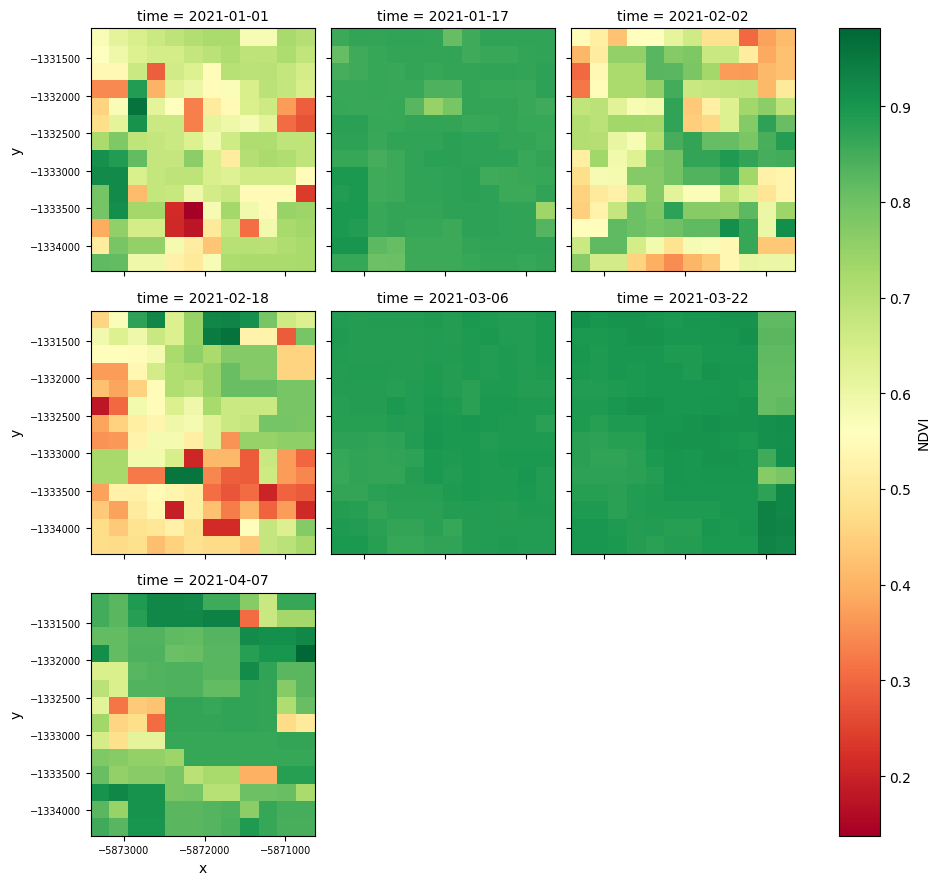

In [21]:
import datetime as dt

import matplotlib.pyplot as plt
import numpy as np
import shapely.geometry

# Área e janela curtas, só para as figuras ficarem legíveis.
cubo_cov = service['mod13q1-6.1']
cubo_poly = shapely.geometry.box(-54.00, -12.00, -53.97, -11.97)
cubo_fim = (dt.date.fromisoformat(INICIO) + dt.timedelta(days=100)).isoformat()
cubo_ts = cubo_cov.ts(attributes=['NDVI'], geom=cubo_poly,
                      start_datetime=INICIO, end_datetime=cubo_fim).ts
cubo = cubo_ts.to_xarray(grid=True)
print('cubo (time, y, x):', dict(cubo.sizes))
print('CRS da grade     :', cubo.attrs['crs'])
print(f'pixel            : {cubo.attrs["res_x"]:.2f} m')

# O cisalhamento em lon/lat: a longitude de uma mesma coluna muda de linha para linha.
lon = cubo['longitude'].values
deriva = lon[:, 0].max() - lon[:, 0].min()
largura = float(np.mean(np.diff(lon, axis=1)))
print(f'longitude da 1ª coluna ao longo das {cubo.sizes["y"]} linhas: varia {deriva:.4f}°, '
      f'{deriva / largura:.1f} vezes a largura de um pixel ({largura:.4f}°)')

# Recorta para o retângulo comum a todas as linhas: a caixa lon/lat corta a grade nativa
# na diagonal, deixando degraus nas bordas.
covered = np.isfinite(cubo['NDVI'].values).any(axis=0)   # (y, x): há dado em alguma data?
cols = np.flatnonzero(covered.all(axis=0))               # colunas presentes em toda linha
sub = cubo.isel(x=slice(cols[0], cols[-1] + 1))
rows = np.flatnonzero(np.isfinite(sub['NDVI'].values).any(axis=0).all(axis=1))
sub = sub.isel(y=slice(rows[0], rows[-1] + 1))
print('recorte desenhado:', dict(sub.sizes))

# Facet: um mapa por data, nos eixos x/y nativos (metros na sinusoidal do MODIS).
grade = sub['NDVI'].plot(x='x', y='y', col='time', col_wrap=3, cmap='RdYlGn')
for ax in grade.axs.flat:
    ax.ticklabel_format(useOffset=False, style='plain')
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
    ax.tick_params(labelsize=7)
plt.show()

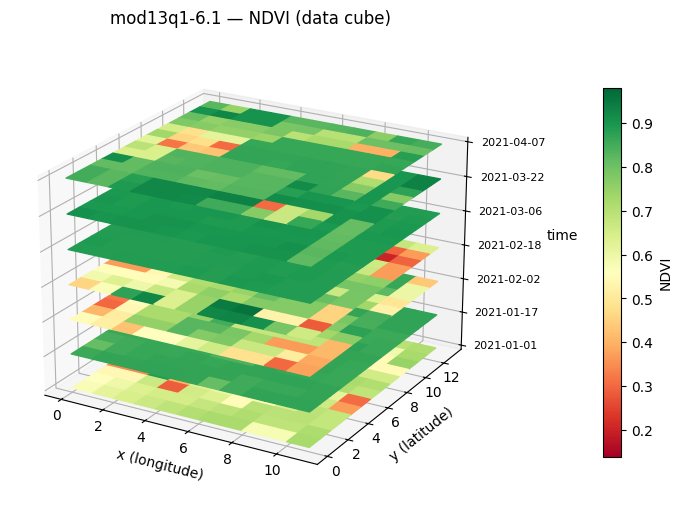

In [22]:
# Cubo 3D: as fatias de tempo empilhadas (uma camada por data)
_ = cubo_ts.plot_cube('NDVI', cmap='RdYlGn')

### 10.7 Gráfico interativo

`plot(interactive=True)` desenha as mesmas séries com **plotly**: o gráfico aceita zoom
e deslocamento, cada ponto mostra data, valor e o pixel de origem ao passar o mouse, e a
legenda liga e desliga as camadas (todos os pixels, quartis, mediana).

Diferente da versão matplotlib, que desenha e não devolve nada, esta **retorna a figura**
— dá para ajustar o layout antes de exibir.

Como navegar no gráfico: **arrastar** dá zoom na área selecionada, a **roda do
mouse** aproxima e afasta, o **duplo clique** volta ao enquadramento inicial e a
**barra no canto superior direito** traz zoom, deslocamento e reset. Clicar num
item da legenda liga e desliga aquela camada.

O parâmetro `limit` vale para as duas versões: ele reduz quantas séries são
desenhadas, e o título passa a anunciar quantas de quantas estão à vista.

> Requer o extra `interactive` (`pip install wtss[interactive]`).

In [23]:
import plotly.io as pio

# 'notebook_connected' carrega o plotly.js de CDN: mantém o notebook leve.
# Troque por 'notebook' para embutir a biblioteca e o gráfico abrir sem internet
# (o arquivo cresce, porque leva a biblioteca inteira).
pio.renderers.default = 'notebook_connected'

# A área tem milhares de pixels. O limit mantém a figura leve sem esconder o
# total, que continua anunciado no título do gráfico.
figura = serie.plot(interactive=True, limit=200)
figura.update_layout(height=420)

figura.show(config={
    'scrollZoom': True,      # roda do mouse dá zoom para dentro e para fora
    'displayModeBar': True,  # barra sempre visível, em vez de só ao passar o mouse
})

### 10.8 Mapa interativo

`plot_map(interactive=True)` devolve um mapa navegável, com base cartográfica, no lugar
da figura estática: **clicar num pixel abre a série daquele ponto**.

O gráfico do popup é SVG puro, sem script nem recurso externo, então funciona também no
HTML exportado. Como é um popup por pixel, `limit` mantém o arquivo leve em áreas grandes.

> Requer o extra `interactive` (`pip install wtss[interactive]`).

In [24]:
# Clique num pixel para ver a série daquele ponto.
# radius é o raio do marcador em pixels (o markersize do mapa estático é área).
mapa = serie.plot_map(ATRIBUTO, reduce='mean', cmap='RdYlGn',
                      interactive=True, limit=200, radius=5)
mapa

## 11. Unidade física (opcional)

Os flags `apply_scale`/`mask_nodata` convertem inteiros crus para a unidade física (aplicam `scale`/`offset` e mascaram `nodata`).

> **Proteção automática:** se o servidor **já** entregar dados escalados (caso das coleções do v4), o cliente **detecta** e emite um aviso, evitando *dupla-escala*. Por isso, para estas coleções, use `apply_scale=False` — os dados já vêm prontos. A célula abaixo mostra essa detecção.

scale declarado da banda: 0.0001
os dados já parecem escalados? True
  -> use apply_scale=False: os dados já estão em unidade física.
     Se ligar apply_scale, o cliente AVISA para evitar dupla-escala.


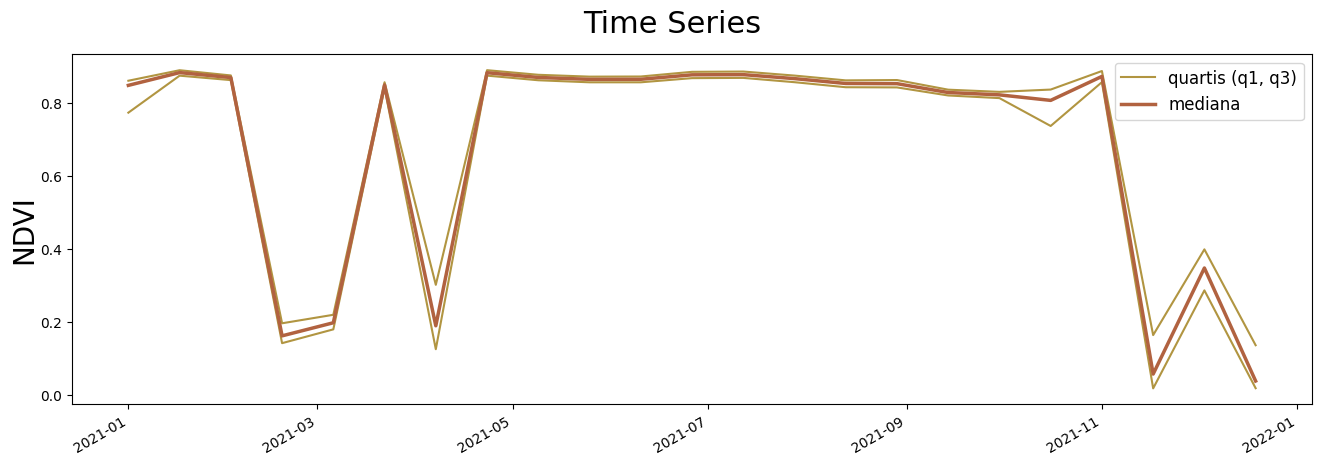

In [25]:
import numpy as np

# A biblioteca detecta dupla-escala com esta heurística: valores já em unidade
# física são floats fracionários, enquanto números digitais crus seriam inteiros.
amostra = serie.df(format='wide').iloc[:, 0].dropna().head(50)
ja_escalado = float(np.mean([float(v) != int(v) for v in amostra])) > 0.5

print('scale declarado da banda:', coverage.band(ATRIBUTO).get('scale'))
print('os dados já parecem escalados?', ja_escalado)
if ja_escalado:
    print('  -> use apply_scale=False: os dados já estão em unidade física.')
    print('     Se ligar apply_scale, o cliente AVISA para evitar dupla-escala.')

# Gráfico em escala nativa — a correta para esta coleção:
serie.plot(pixels=False)

## 12. 🛰️ Generalidade — o mesmo código em vários sensores

O grande valor do WTSS é padronizar sensores diferentes atrás da **mesma interface**. Abaixo pedimos o **NDVI no mesmo ponto e período** para Sentinel-2, Landsat, MODIS e CBERS, e sobrepomos tudo num só gráfico para comparar.

Repare que cada sensor tem **cadência e resolução próprias** (mais ou menos pontos no tempo), mas o código é idêntico — só muda o nome da coleção.

In [26]:
import pandas as pd

SENSORES = ['S2-16D-2', 'LANDSAT-16D-1', 'mod13q1-6.1', 'CBERS-WFI-8D-1']

colunas = {}
for nome in SENSORES:
    serie_ndvi = service[nome].ts(attributes=['NDVI'],
                                  latitude=LATITUDE, longitude=LONGITUDE,
                                  start_datetime=INICIO, end_datetime=FIM).ts['NDVI']
    # NDVI físico vive em [-1, 1]; descarta sentinelas de nodata (ex.: -9999).
    colunas[nome] = serie_ndvi[serie_ndvi.between(-1, 1)]

comparacao = pd.DataFrame(colunas)
comparacao.describe()

,S2-16D-2,LANDSAT-16D-1,mod13q1-6.1,CBERS-WFI-8D-1
count,23.000000,23.000000,23.000000,45.000000
mean,0.644713,0.715991,0.839326,0.688176
std,0.328112,0.275149,0.081628,0.252007
min,0.008100,-0.017000,0.572000,0.113600
25%,0.324550,0.740350,0.844300,0.699800
50%,0.861900,0.849600,0.862500,0.805300
75%,0.876500,0.859550,0.881950,0.832700
max,0.896100,0.887500,0.901100,1.000000


Text(0, 0.5, 'NDVI')

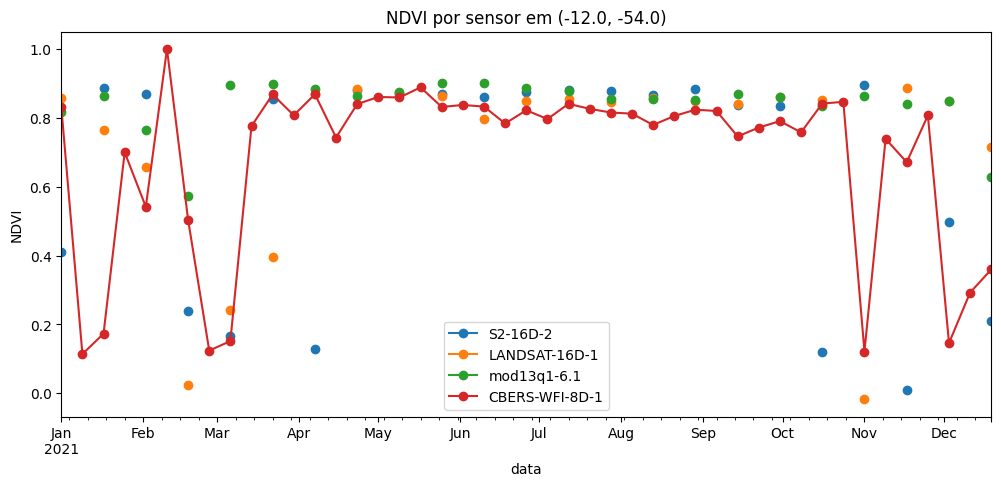

In [27]:
ax = comparacao.plot(marker='o', figsize=(12, 5),
                     title=f'NDVI por sensor em ({LATITUDE}, {LONGITUDE})')
ax.set_xlabel('data'); ax.set_ylabel('NDVI')

## 13. Além da vegetação

WTSS não serve só índices de vegetação. Há coleções de **temperatura da superfície** (`mod11a2-6.1` / `myd11a2-6.1`, banda `LST_Day_1km`), **refletâncias por banda** (`red`, `nir08`, `swir16` no Landsat; `B02`..`B12` no Sentinel-2) e **máscaras de qualidade**. O procedimento é o mesmo: descubra as bandas no laço da seção 4 e troque `ATRIBUTO` na configuração.

## 14. Linha de comando (CLI)

Ao instalar o pacote você ganha o comando `wtss`. As células abaixo usam `!` para executar o terminal a partir do notebook.

In [28]:
!wtss --version

wtss, version 2.0.0a4


In [29]:
# Listar coleções do servidor:
!wtss list-coverages --url https://data.inpe.br/bdc/wtss/v4/

CBERS4-MUX-2M-1
CBERS4-WFI-16D-2
CBERS-WFI-8D-1
LANDSAT-16D-1
mod11a2-6.1
mod13q1-6.1
myd11a2-6.1
myd13q1-6.1
S2-16D-2


In [30]:
# Descrever uma coleção (metadados em JSON):
!wtss describe --coverage S2-16D-2 --url https://data.inpe.br/bdc/wtss/v4/

	- Coverage(service=wtss(url="https://data.inpe.br/bdc/wtss/v4/",validate=False,access_token=None), id=S2-16D-2)


In [31]:
# Recuperar uma série num ponto (troque coverage/attributes à vontade):
!wtss ts --coverage S2-16D-2 --attributes NDVI --longitude -54 --latitude -12 --start-datetime 2021-01-01 --end-datetime 2021-12-31 --url https://data.inpe.br/bdc/wtss/v4/

	NDVI: [[0.4094, 0.8863, 0.8686, 0.2397, 0.1666, 0.8541, 0.1298, 0.8801, 0.8726, 0.8683, 0.8619, 0.8759, 0.8817, 0.8771, 0.8677, 0.8844, 0.8374, 0.8352, 0.1194, 0.8961, 0.0081, 0.4969, 0.2111]]
	timeline: ['2021-01-01', '2021-01-17', '2021-02-02', '2021-02-18', '2021-03-06', '2021-03-22', '2021-04-07', '2021-04-23', '2021-05-09', '2021-05-25', '2021-06-10', '2021-06-26', '2021-07-12', '2021-07-28', '2021-08-13', '2021-08-29', '2021-09-14', '2021-09-30', '2021-10-16', '2021-11-01', '2021-11-17', '2021-12-03', '2021-12-19']


In [32]:
# Ajuda geral:
!wtss --help

Usage: wtss [OPTIONS] COMMAND [ARGS]...

  Database commands.

  .. note:: You can invoke more than one subcommand in one go.

Options:
  --version  Show the version and exit.
  --help     Show this message and exit.

Commands:
  describe        Retrieve the coverage metadata.
  list-coverages  List available coverages.
  ts              Retrieve the coverage metadata.


---

### Próximos passos

- Volte à **seção 5** e troque `COBERTURA`/`ATRIBUTO` para aplicar tudo a outro satélite ou variável — o notebook inteiro reexecuta sem mais mudanças.